# Sizing of Amplifier & Filter

**Copyright 2026 Simon Dorrer and Harald Pretl**

SPDX-License-Identifier: Apache-2.0 WITH SHL-2.1

## Imports, Constants and Filepaths

In [1]:
# Imports
import math
from spice_params import read_spice_params, write_spice_params
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from pygmid import Lookup as lk
from pygmid import Lookup as lk
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
# Constants
k_b = 1.380649e-23 #J/K
gamma = 2/3
T = 130+273.15 # worst case die temperature in Kelvin
# Filepaths
PASSIVES_SIZING ='filterPassivesSizing.spice'

In [44]:
# Round contour levels (steps of 1, 2 or 5 times a power of ten) over the range of z
def nice_levels(z, n=15):
    return MaxNLocator(n, steps=[1, 2, 5, 10]).tick_values(np.nanmin(z), np.nanmax(z))


# Frequency with unit prefix, for contour labels
def fmt_hz(f):
    for div, unit in ((1e9, 'GHz'), (1e6, 'MHz'), (1e3, 'kHz')):
        if f >= div:
            return f'{f/div:g} {unit}'
    return f'{f:g} Hz'

## Functions for plotting

In [2]:
# Round contour levels (steps of 1, 2 or 5 times a power of ten) over the range of z
def nice_levels(z, n=15):
    return MaxNLocator(n, steps=[1, 2, 5, 10]).tick_values(np.nanmin(z), np.nanmax(z))


# Frequency with unit prefix, for contour labels
def fmt_hz(f):
    for div, unit in ((1e9, 'GHz'), (1e6, 'MHz'), (1e3, 'kHz')):
        if f >= div:
            return f'{f/div:g} {unit}'
    return f'{f:g} Hz'

# Specifications

In [3]:
### SYSTEM LEVEL ###

# Start frequency [Hz]
fstart = 100

# Pass-band frequency (-3dB) [Hz]
fpass = 1e6

# Stop-band frequency (fs-fpass) [Hz]
fstop = 9e6

B = fstop - fstart
# Pass-band gain [dB]
Apass = 20

# Pass-band ripple [dB] (allowed)
Rpass = 0.1

# Stop-band attenuation [dB]
astop =49.9

# Maximum Filter order
maxord = 4

# Input/Output structure type
iostruct = "fully differential"

# Maximum number of amplifiers
maxamps = 2

# Max. SNDR (limited by ADC) [dB]
SNDRmax = 48.6

# Noise gain
beta = 1 / (1+10**(Apass/20))

In [4]:
### CHIP LEVEL ###

# Supply voltage
VDD = 1.5

# Input common-mode voltage
Vcm_in = VDD / 2

# Output common-mode voltage
Vcm_out = VDD / 2

# Maximum output signal [V]
Vfs = 1

# Load resistance [Ω]
Rl = 560e3

# Load capacitance [F]
Cl = 5e-12

# Maximum integrated output-referred noise 100Hz to fstop [V]
onoise = 113e-6

# OTA unity-gain bandwidth [Hz]
fug = 10e6 # naive approach
fug = 30*1*fpass/beta # approach of (10 to 100 -> 30)*Q(1)*fn(fpass)/beta0(1/11)

# Gain error [%]
epsilong = 1e6 # still to be determined

# Maximum chip area [μm²]
area = 200*200

# Maximum total power [W]
Ptot = 100e-6

# Maximum filter THD @ Vfs [dBc]
THDfilt = -60

# Number of bits of the ADC [bits]
nadc = 8

# Passband frequency [Hz]
fpass = 1e6

# Stopband frequency for use with digital decimator [Hz]
fstop_decimator = 9e6

# Stopband frequency [Hz]
fstop = 5e6

In [5]:
# Print Specifications
print("=" * 60)
print("Specifications:")
print("=" * 60)
print(f"Maximum output signal (Vfs) differential: {Vfs} V")
print(f"Load impedance:                           {Rl*1e-3} kΩ || {Cl*1e12} pF")
print(f"Integrated output-referred noise :       ≤{onoise*1e6} μV")
print(f"OTA unity-gain bandwidth fug:            >{fug*1e-6} MHz")
print(f"Gain error εg:                            {epsilong} %")
print(f"Supply voltage VDD:                       {VDD} V")
print(f"Maximum chip area:                       <{area} μm²")
print(f"Total power:                             <{Ptot*1e6} μW")
print(f"Filter THD @ Vfs:                        ≤{THDfilt} dBc")
print(f"Number of bits:                           {nadc}")
print(f"Passband frequency:                       {fpass*1e-6} MHz")
print(f"Stopband frequency w/ dig. decimator:     {fstop_decimator*1e-6} MHz")
print(f"Stopband frequency w/o dig. decimator:    {fstop*1e-6} MHz")
print("=" * 60)

Specifications:
Maximum output signal (Vfs) differential: 1 V
Load impedance:                           560.0 kΩ || 5.0 pF
Integrated output-referred noise :       ≤113.0 μV
OTA unity-gain bandwidth fug:            >330.0 MHz
Gain error εg:                            1000000.0 %
Supply voltage VDD:                       1.5 V
Maximum chip area:                       <40000 μm²
Total power:                             <100.0 μW
Filter THD @ Vfs:                        ≤-60 dBc
Number of bits:                           8
Passband frequency:                       1.0 MHz
Stopband frequency w/ dig. decimator:     9.0 MHz
Stopband frequency w/o dig. decimator:    5.0 MHz


Specifications:
Maximum output signal (Vfs) differential: 1 V
Load impedance:                           560.0 kΩ || 5.0 pF
Integrated output-referred noise :       ≤113.0 μV
OTA unity-gain bandwidth fug:            >330.0 MHz
Gain error εg:                            1000000.0 %
Supply voltage VDD:                       1.5 V
Maximum chip area:                       <40000 μm²
Total power:                             <100.0 μW
Filter THD @ Vfs:                        ≤-60 dBc
Number of bits:                           8
Passband frequency:                       1.0 MHz
Stopband frequency w/ dig. decimator:     9.0 MHz
Stopband frequency w/o dig. decimator:    5.0 MHz


In [6]:
# Peak SQNR w/ FS sine [dB]
sqnr_peak = 6.02 * nadc + 1.76
# LSB Volage for n bits[V]
Vlsb = Vfs/2**nadc
# Quantization noise for uniform distribution
Vqn = Vlsb/math.sqrt(12)
# Output Swing in RMS
Vorms = Vfs/(2*math.sqrt(2))
# Peak SNR for given noise and output power
SNRpeak = 10*math.log10(Vorms**2/(Vqn**2+onoise**2))

A0_dB = 20*math.log10(fug/fpass)
A0 = 10**(A0_dB/20)
#A0 = gm*R0
#In^2 = 2*4*k_b*T*gamma*gm*B
#In^2 = 2*4*k_b*T*gamma*B*A0/Ro
#Von^2=Ro^2*In^2=2*4*k_b*T*gamma*B*A0*Ro
#Von = Ro*In
#In^2*R0^2=In^2*A0^2/gm^2=8*k_b*T*gamma*B*gm*A0^2/gm^2
#=8*k_b*T*gamma*B*A^2/gm
# fehler in rechnung fixen, letzte rechnung stimmt aber herleitungen passen so nicht
# Stage-1 load M12/M13 adds its channel noise: factor (1 + gm_load/gm_DP),
# i.e. 1 + (gm/Id)_load/(gm/Id)_DP at equal currents; keep consistent with gm_id_DP_Load/gm_id_DP below
gm_id_ratio_load = 1
gm_min = (1 + gm_id_ratio_load) * 8*k_b*T*gamma*B*(1/beta)**2 / onoise**2
#gm_min = onoise **2 / (2*4*k_b*gamma*(273.15+130)*(fstop-fstart))
Ro_min = A0/gm_min
Cpole = gm_min/(2*math.pi*fug)

In [7]:
# Print Specifications
print("=" * 60)
print("Noise:")
print("=" * 60)
print(f"SQNR_peak:                  {sqnr_peak:.3f} dB")
print(f"Vlsb:                       {Vlsb*1e3:.3f} mV")
print(f"Quantisation noise Voltage: {Vqn*1e3:.3f} mVrms")
print(f"Output voltage:             {Vorms*1e3:.3f} mVrms")
print(f"SNR_peak:                   {SNRpeak:.3f} dB")
print(f"DC-Gain required:           {A0_dB:.3f} dB")
print(f"Required gm:                {gm_min*1e3:.3f} mS")
print(f"Required Ro:                {Ro_min*1e-3:.3f} kOhm")
print(f"Co for pole at fug:         {Cpole*1e12:.3f} pF")
print("=" * 60)

Noise:
SQNR_peak:                  49.920 dB
Vlsb:                       3.906 mV
Quantisation noise Voltage: 1.128 mVrms
Output voltage:             353.553 mVrms
SNR_peak:                   49.882 dB
DC-Gain required:           50.370 dB
Required gm:                5.063 mS
Required Ro:                65.173 kOhm
Co for pole at fug:         2.442 pF


Noise:
SQNR_peak:                  49.920 dB
Vlsb:                       3.906 mV
Quantisation noise Voltage: 1.128 mVrms
Output voltage:             353.553 mVrms
SNR_peak:                   49.882 dB
DC-Gain required:           50.370 dB
Required gm:                5.063 mS
Required Ro:                65.173 kOhm
Co for pole at fug:         2.442 pF


# Load SG13CMOS5L Data Tables

In [8]:
lv_nmos = lk('data/sg13cmos5l_lv_nmos.mat')
lv_pmos = lk('data/sg13cmos5l_lv_pmos.mat')
# list of parameters: VGS, VDS, VSB, L, W, NFING, ID, VT, GM, GMB, GDS, CGG, CGB, CGD, CGS, CDD, CSS, STH, SFL
# if not specified, minimum L, VDS=max(vgs)/2=0.9 and VSB=0 are used 

# Filter Components Sizing

In [9]:
C_per_area = 1.287e-15 # pF/μm² für cmomf
# C = C_per_area * W*L
R_square = 1.645e3 # kΩ/quare für rhigh
# R = R_square * L/W

In [10]:
passives = read_spice_params("filterPassives.spice")
R1 = passives.get("R1")
R2 = passives.get("R2")
R3 = passives.get("R3")
R4 = passives.get("R4")

C1 = passives.get("C1")
C2 = passives.get("C2")
C3 = passives.get("C3")

W_R = 0.5 # 0.5μm
L_R1_exact = R1 / R_square * W_R
L_R2_exact = R2 / R_square * W_R
L_R3_exact = R3 / R_square * W_R
L_R4_exact = R4 / R_square * W_R

L_R1 = round(L_R1_exact / 0.5)*0.5
L_R2 = round(L_R2_exact / 0.5)*0.5
L_R3 = round(L_R3_exact / 0.5)*0.5
L_R4 = round(L_R4_exact / 0.5)*0.5

d_R1 = (L_R1_exact - L_R1) / W_R * R_square
d_R2 = (L_R2_exact - L_R2) / W_R * R_square
d_R3 = (L_R3_exact - L_R3) / W_R * R_square
d_R4 = (L_R4_exact - L_R4) / W_R * R_square

e_R1 = d_R1 / R1 * 100
e_R2 = d_R2 / R2 * 100
e_R3 = d_R3 / R3 * 100
e_R4 = d_R4 / R4 * 100

C_1_Area = C1 / C_per_area
C_2_Area = C2 / C_per_area
C_3_Area = C3 / C_per_area

L_C1_exact = math.sqrt(C_1_Area)
L_C2_exact = math.sqrt(C_2_Area)
L_C3_exact = math.sqrt(C_3_Area)

L_C1 = round(L_C1_exact/0.5)*0.5
L_C2 = round(L_C2_exact/0.5)*0.5
L_C3 = round(L_C3_exact/0.5)*0.5

d_C1 = C1 - C_per_area * L_C1**2
d_C2 = C2 - C_per_area * L_C2**2
d_C3 = C3 - C_per_area * L_C3**2

e_C1 = d_C1 / C1 * 100
e_C2 = d_C2 / C2 * 100
e_C3 = d_C3 / C3 * 100


In [11]:
# Passives area estimation
A_Res_Filter = W_R * (L_R1 + L_R2 + L_R3 + L_R4)
A_Cap_Filter = L_C1**2 + L_C2**2 + L_C3**2
A_Passives_Filter = A_Res_Filter + A_Cap_Filter
L_Passives_equiv = math.sqrt(A_Passives_Filter)

In [12]:
print("=" * 60)
print("Filter Passives Sizing:")
print("=" * 60)
print(f"W R:  {W_R}  μm")
print(f"L R1: {L_R1_exact:.3f} μm, rounded: {L_R1} μm")
print(f"L R2: {L_R2_exact:.3f} μm, rounded: {L_R2} μm")
print(f"L R3: {L_R3_exact:.3f} μm, rounded: {L_R3} μm")
print(f"L R4: {L_R4_exact:.3f} μm, rounded: {L_R4} μm")
print(f"L C1: {L_C1_exact:.3f} μm, rounded: {L_C1} μm")
print(f"L C2: {L_C2_exact:.3f} μm, rounded: {L_C2} μm")
print(f"L C3: {L_C3_exact:.3f} μm, rounded: {L_C3} μm")
print("=" * 60)
print("Deviation from exact target:")
print("=" * 60)
print(f"ΔR1: {d_R1:.3f} Ω, relative: {e_R1:.3f} %")
print(f"ΔR2: {d_R2:.3f} Ω, relative: {e_R2:.3f} %")
print(f"ΔR3: {d_R3:.3f} Ω, relative: {e_R3:.3f} %")
print(f"ΔR4: {d_R4:.3f} Ω, relative: {e_R4:.3f} %")
print(f"ΔC1: {d_C1*1e15:.3f} fF, relative: {e_C1:.3f} %")
print(f"ΔC2: {d_C2*1e15:.3f} fF, relative: {e_C2:.3f} %")
print(f"ΔC3: {d_C3*1e15:.3f} fF, relative: {e_C3:.3f} %")
print("=" * 60)
print("Minimum Passives Area (unreachable - 100% fill)")
print("=" * 60)
print(f"Resistor Area: {A_Res_Filter} μm²")
print(f"Capacitor Area: {A_Cap_Filter} μm²")
print(f"Filter passives Area: {A_Passives_Filter} μm²")
print(f"Filter passives side-lengt (assumes a square): {L_Passives_equiv:.3f} μm")
print("=" * 60)

Filter Passives Sizing:
W R:  0.5  μm
L R1: 3.162 μm, rounded: 3.0 μm
L R2: 31.618 μm, rounded: 31.5 μm
L R3: 5.921 μm, rounded: 6.0 μm
L R4: 48.375 μm, rounded: 48.5 μm
L C1: 139.374 μm, rounded: 139.5 μm
L C2: 19.710 μm, rounded: 19.5 μm
L C3: 27.875 μm, rounded: 28.0 μm
Deviation from exact target:
ΔR1: 532.200 Ω, relative: 5.116 %
ΔR2: 387.100 Ω, relative: 0.372 %
ΔR3: -259.300 Ω, relative: -1.331 %
ΔR4: -410.100 Ω, relative: -0.258 %
ΔC1: -45.342 fF, relative: -0.181 %
ΔC2: 10.618 fF, relative: 2.124 %
ΔC3: -9.008 fF, relative: -0.901 %
Minimum Passives Area (unreachable - 100% fill)
Resistor Area: 44.5 μm²
Capacitor Area: 20624.5 μm²
Filter passives Area: 20669.0 μm²
Filter passives side-lengt (assumes a square): 143.767 μm


Filter Passives Sizing:
W R:  0.5  μm
L R1: 3.162 μm, rounded: 3.0 μm
L R2: 31.618 μm, rounded: 31.5 μm
L R3: 5.921 μm, rounded: 6.0 μm
L R4: 48.375 μm, rounded: 48.5 μm
L C1: 139.374 μm, rounded: 139.5 μm
L C2: 19.710 μm, rounded: 19.5 μm
L C3: 27.875 μm, rounded: 28.0 μm
Deviation from exact target:
ΔR1: 532.200 Ω, relative: 5.116 %
ΔR2: 387.100 Ω, relative: 0.372 %
ΔR3: -259.300 Ω, relative: -1.331 %
ΔR4: -410.100 Ω, relative: -0.258 %
ΔC1: -45.342 fF, relative: -0.181 %
ΔC2: 10.618 fF, relative: 2.124 %
ΔC3: -9.008 fF, relative: -0.901 %
Minimum Passives Area (unreachable - 100% fill)
Resistor Area: 44.5 μm²
Capacitor Area: 20624.5 μm²
Filter passives Area: 20669.0 μm²
Filter passives side-lengt (assumes a square): 143.767 μm


## Write sizing to spice param file

In [13]:
passives_sizing = {'W_R': W_R, 'L_R1': L_R1, 'L_R2': L_R2, 'L_R3': L_R3, 'L_R4': L_R4, 'L_C1': L_C1, 'L_C2': L_C2, 'L_C3': L_C3}
write_spice_params(passives_sizing, PASSIVES_SIZING, microns=True)

Wrote 8 parameters to filterPassivesSizing.spice


Wrote 8 parameters to filterPassivesSizing.spice


## Noise Budget

In [14]:
# Output-referred noise of the complete filter with an ideal OTA, per half circuit:
# MFB biquad (R1, R2, R3, C1, C2) followed by the passive RC section (R4, C3).
# C1 and C3 are per-half values. A differential capacitor Cd between the two halves
# acts as 2*Cd per half, so it has to be built as Cd = C/2.
trapz = getattr(np, 'trapezoid', None) or np.trapz
f_noise = np.logspace(np.log10(fstart), np.log10(fstart + B), 4001)
s_noise = 2j * np.pi * f_noise

Y_X = 1/R1 + 1/R2 + 1/R3 + s_noise*C1      # admittance sum at the inner node of the MFB
D_noise = 1/R2 + Y_X*R3*s_noise*C2
H_RC = 1 / (1 + s_noise*R4*C3)

# Transfer functions from each resistor's noise voltage to the filter output
tf_noise = {
    'R1': -(1/R1) / D_noise * H_RC,          # same as the signal path
    'R2': -(1/R2) / D_noise * H_RC,
    'R3': -(Y_X - 1/R3) / D_noise * H_RC,
    'R4': H_RC,
}
R_noise = {'R1': R1, 'R2': R2, 'R3': R3, 'R4': R4}
# Noise gain from the OTA input to the filter output (11 at DC, peaks near fpass)
ng_ota = (Y_X*R3*s_noise*C2 + Y_X - 1/R3) / D_noise * H_RC

# Differential output noise power; the two halves add up for the resistors
vn2_res = {k: 2 * trapz(4*k_b*T*R_noise[k]*np.abs(h)**2, f_noise) for k, h in tf_noise.items()}
vn2_res_tot = sum(vn2_res.values())
vn2_left = onoise**2 - vn2_res_tot
int_ng2 = trapz(np.abs(ng_ota)**2, f_noise)

# gm of the input pair if the OTA may use this share of the noise power budget
ota_noise_share = 0.5
gm_noise = 8*k_b*T*gamma*(1 + gm_id_ratio_load)*int_ng2 / (ota_noise_share*onoise**2)

In [15]:
print("=" * 60)
print(f"Noise Budget (ideal OTA, {fstart:.0f} Hz to {(fstart + B)*1e-6:.1f} MHz, {T:.0f} K):")
print("=" * 60)
print(f"Check, signal gain at fstart: {np.abs(tf_noise['R1'][0]):.2f} (expected {10**(Apass/20):.2f})")
for k, v in vn2_res.items():
    print(f"Resistor {k}:                  {np.sqrt(v)*1e6:.1f} μV")
print(f"All resistors:                {np.sqrt(vn2_res_tot)*1e6:.1f} μV")
print(f"Budget:                       {onoise*1e6:.1f} μV")
if vn2_left <= 0:
    print("Note! Resistor noise alone exceeds the noise budget!")
else:
    print(f"Left for the OTA:             {np.sqrt(vn2_left)*1e6:.1f} μV")
print("-" * 60)
print(f"Integrated noise gain^2:      {int_ng2:.3g} Hz, flat (1/beta)^2*B: {(1/beta)**2*B:.3g} Hz")
print(f"gm for {ota_noise_share*100:.0f} % of the budget:    {gm_noise*1e3:.3f} mS, flat estimate (gm_min): {gm_min*1e3:.3f} mS")
print("=" * 60)

Noise Budget (ideal OTA, 100 Hz to 9.0 MHz, 403 K):
Check, signal gain at fstart: 10.00 (expected 10.00)
Resistor R1:                  220.2 μV
Resistor R2:                  69.6 μV
Resistor R3:                  480.7 μV
Resistor R4:                  101.7 μV
All resistors:                542.9 μV
Budget:                       113.0 μV
Note! Resistor noise alone exceeds the noise budget!
------------------------------------------------------------
Integrated noise gain^2:      2.73e+08 Hz, flat (1/beta)^2*B: 1.09e+09 Hz
gm for 50 % of the budget:    2.543 mS, flat estimate (gm_min): 5.063 mS


Noise Budget (ideal OTA, 100 Hz to 9.0 MHz, 403 K):
Check, signal gain at fstart: 10.00 (expected 10.00)
Resistor R1:                  220.2 μV
Resistor R2:                  69.6 μV
Resistor R3:                  480.7 μV
Resistor R4:                  101.7 μV
All resistors:                542.9 μV
Budget:                       113.0 μV
Note! Resistor noise alone exceeds the noise budget!
------------------------------------------------------------
Integrated noise gain^2:      2.73e+08 Hz, flat (1/beta)^2*B: 1.09e+09 Hz
gm for 50 % of the budget:    2.543 mS, flat estimate (gm_min): 5.063 mS


## Power Budget

In [16]:
i_tot_targ = Ptot / VDD
# 66.7μA allowed for 100μW power target
# Main expenses: Output Stage + Input Stage
# Current reference paths ~ 1/10 of input stage
# Output stage ~ 2 * input stage
# Total: 2*1/10 + 2*2 + 1 = 5.2
i_unit = i_tot_targ / 5.2
id_diode_bias = 0.1 * i_unit
id_input_bias = i_unit
id_output_mirror = 2 * i_unit

print(f"Current Budget for {Ptot*1e6} μW Power Target")
print(f"I_total:       {i_tot_targ*1e6:.3f} μA")
print(f"ID Bias Gen:   {id_diode_bias*1e6:.3f} μA")
print(f"ID Input Bias: {id_input_bias*1e6:.3f} μA")
print(f"ID Output Stage: {id_output_mirror*1e6:.3f} μA each")

Current Budget for 100.0 μW Power Target
I_total:       66.667 μA
ID Bias Gen:   1.282 μA
ID Input Bias: 12.821 μA
ID Output Stage: 25.641 μA each


## Violation of Noise Budget guaranteed 
The resistors break the noise budget by more than the Amp was ever allowed to have.  
The resistors can only get smaller if the capacitances increase and they are already at half the area allowed for C1 alone.  
So: noise budget secondary and <b>power budget primary</b>.

# OTA Sizing

## Simulated Voltages

In [17]:
# Measured DC OP Values for more accurate lookups
viref1 = 1.121
vo1_n = 0.386
vo1_p = 0.386
vbn = 0.2
# Switch for using the educated guess values or using the op data values
sw_use_op = False
if sw_use_op:
    v_ds_dp = (2 * viref1 - vo1_n - vo1_p ) / 2
    vds_dp_load = (vo1_n + vo1_p) / 2
    vds_diode_bias = VDD - vbn
else:
    vds_dp = VDD/2
    vds_dp_load = VDD/2
    vds_diode_bias = VDD/2

In [59]:
dev = lv_nmos      # device for all plots below
dev_name = 'LV NMOS'


# Achslängen für Contour Plot
x_plt_len = 23
y_plt_len = 23

# Achsen für Contour Plot
gm_id_DP = np.linspace(3, 10, x_plt_len)       # Diffpair gm/Id [S/A]
gm_id_DP_Load = np.linspace(3, 25, y_plt_len)  # Diffpair Load gm/Id [S/A]
A0_FS = np.zeros((x_plt_len, y_plt_len))  # Gain of first Stage [1]
#np.geomspace(0.13, 10, 60)       # [µm]

x_plt = gm_id_DP
y_plt = gm_id_DP_Load

X, Y = np.meshgrid(x_plt, y_plt)   # grid with the same shape as the tables

VDS = 0.35
for i in range(x_plt_len):
    for j in range(y_plt_len):
        id_DP_ = gm_min / gm_id_DP[i]
        gm_DP_Load_ = gm_id_DP_Load[j] * id_DP_
        gds_DP_Load_ = gm_DP_Load_ / lv_nmos.lookup('GM_GDS', GM_ID=gm_id_DP_Load[j], L=0.5, VDS=VDS, VSB=0)
        A0_FS[i,j] = gm_min / gds_DP_Load_


print(A0_FS.shape, x_plt.shape, y_plt.shape)

(23, 23) (23,) (23,)


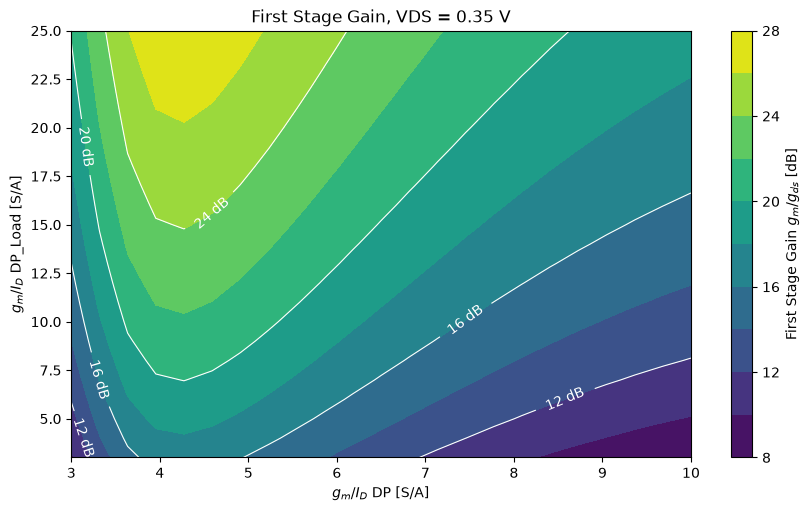

In [61]:
# 2D-Contour Plot
A0_FS_dB = 20*np.log10(A0_FS)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
cf = ax.contourf(X, Y, A0_FS_dB, levels=nice_levels(A0_FS_dB), cmap='viridis')
fig.colorbar(cf, ax=ax, label='First Stage Gain $g_m/g_{ds}$ [dB]')
cs = ax.contour(X, Y, A0_FS_dB, levels=cf.levels[::2], colors='white', linewidths=0.8)
ax.clabel(cs, fmt='%g dB')
ax.set(xlabel='$g_m/I_D$ DP [S/A]', ylabel='$g_m/I_D$ DP_Load [S/A]', yscale='linear',
       title=f'First Stage Gain, VDS = {VDS} V')
plt.show()

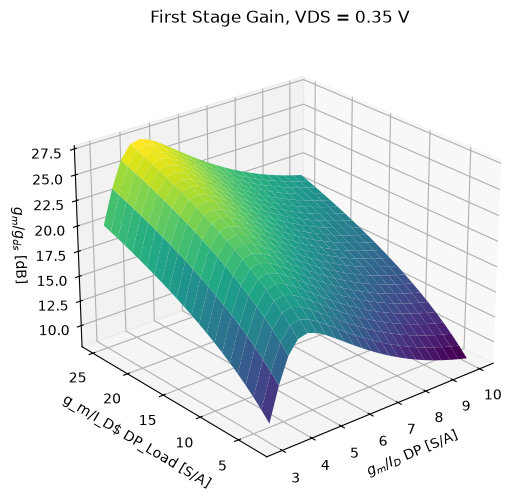

In [62]:
# 3D Surface plot
fig = plt.figure(figsize=(9, 6))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(X, Y, A0_FS_dB, cmap='viridis')
ax.set(xlabel='$g_m/I_D$ DP [S/A]', ylabel='g_m/I_D$ DP_Load [S/A]', zlabel='$g_m/g_{ds}$ [dB]',
       title=f'First Stage Gain, VDS = {VDS} V')
ax.view_init(elev=25, azim=-130)
plt.show()

## Bias Current Generation

In [18]:
gm_id_diode_bias = np.linspace(4, 25, 85)       # [S/A]
L_diode_bias = np.geomspace(0.13, 10, 60)       # [µm]
VDS_diode_bias = 0.75                           # [V], used for the 2D plots
vgs_diode_bias = np.zeros((len(gm_id_diode_bias), len(L_diode_bias)))
# With gm/ID as input (mode 3), pygmid returns an array of shape (len(L), len(gm_id))
gm_gds_diode_bias = lv_pmos.lookup('GM_GDS', GM_ID=gm_id_diode_bias, L=L_diode_bias, VDS=VDS_diode_bias, VSB=0) # intrinsic gain [V/V]
gm_cgg_diode_bias = lv_pmos.lookup('GM_CGG', GM_ID=gm_id_diode_bias, L=L_diode_bias, VDS=VDS_diode_bias, VSB=0) # transit frequency [Hz]
rds_diode_bias = gm_gds_diode_bias / (gm_id_diode_bias * id_diode_bias) 
w_diode_bias = id_diode_bias / lv_pmos.lookup('ID_W', GM_ID=gm_id_diode_bias, L=L_diode_bias, VDS=VDS_diode_bias, VSB=0) # transit frequency [Hz]
for i, gm_id in enumerate(gm_id_diode_bias):
    for j, L in enumerate(L_diode_bias):
        vgs_diode_bias[i,j] = lv_pmos.lookupVGS(GM_ID=gm_id, L=L, VDS=0.75, VSB=0)
vgs_diode_bias = vgs_diode_bias.T
X, Y = np.meshgrid(gm_id_diode_bias, L_diode_bias)   # grid with the same shape as the tables

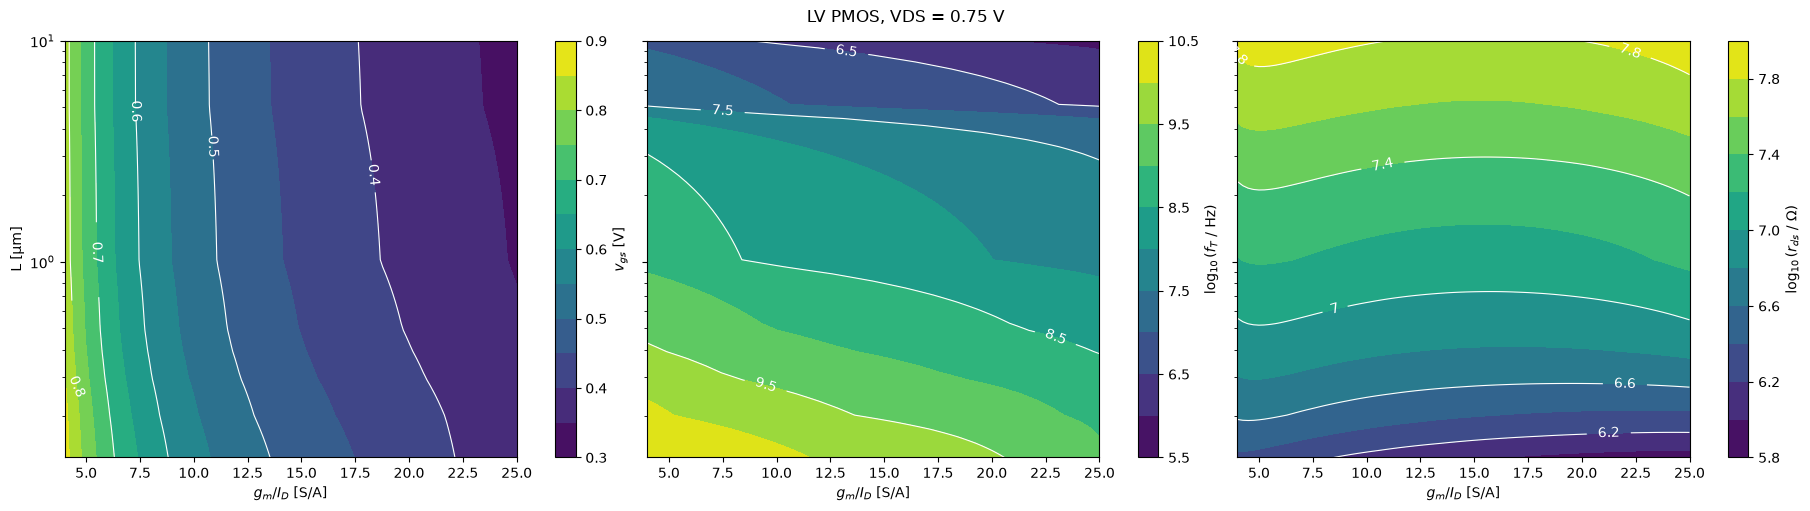

In [19]:
gm_gds_diode_bias_dB = 20*np.log10(gm_gds_diode_bias)
fT_diode_bias = gm_cgg_diode_bias / (2*np.pi)          # GM_CGG ist omega_T [rad/s] -> fT [Hz]

# (Daten, Colorbar-Label, Format der Linienbeschriftung)
plots = [
    (vgs_diode_bias,        '$v_{gs}$ [V]',            '%g'),
    (np.log10(fT_diode_bias),     '$\\log_{10}(f_T$ / Hz)',       '%g'),
    (np.log10(rds_diode_bias),   '$\\log_{10}(r_{ds}$ / $\\Omega$)', '%g'),
]

fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True, constrained_layout=True)
for ax, (z, label, fmt) in zip(axs, plots):
    cf = ax.contourf(X, Y, z, levels=nice_levels(z), cmap='viridis')
    fig.colorbar(cf, ax=ax, label=label)
    cs = ax.contour(X, Y, z, levels=cf.levels[::2], colors='white', linewidths=0.8)
    ax.clabel(cs, fmt=fmt)
    ax.set(xlabel='$g_m/I_D$ [S/A]', yscale='log')
axs[0].set_ylabel('L [µm]')
fig.suptitle(f'LV PMOS, VDS = {VDS_diode_bias} V')
plt.show()


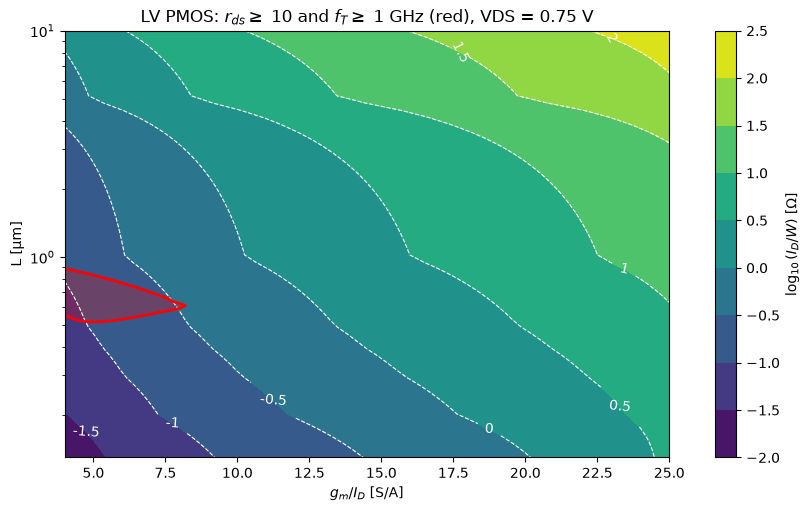

In [20]:
rds_min = 10e6      # [Ohm], placeholder
fT_min = 1e9       # [Hz], placeholder
# >= 1 where both specs are met; a continuous function gives a smooth border, a True/False mask a jagged one
margin = np.minimum(rds_diode_bias/rds_min, fT_diode_bias/fT_min)

fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
cf = ax.contourf(X, Y, np.log10(w_diode_bias), levels=nice_levels(np.log10(w_diode_bias)), cmap='viridis')
fig.colorbar(cf, ax=ax, label='$\\log_{10}(I_D/W)$ [$\\Omega$]')
cs = ax.contour(X, Y, np.log10(w_diode_bias), levels=nice_levels(np.log10(w_diode_bias)), colors='white', linewidths=0.8, linestyles='--')
ax.clabel(cs, fmt=fmt)
ax.contourf(X, Y, margin, levels=[1, margin.max() + 1], colors='red', alpha=0.25)
ax.contour(X, Y, margin, levels=[1], colors='red', linewidths=2)
ax.set(xlabel='$g_m/I_D$ [S/A]', ylabel='L [µm]', yscale='log',
       title=f'LV PMOS: $r_{{ds}} \\geq$ {rds_min*1e-6:g} and $f_T \\geq$ {fT_min*1e-9:g} GHz (red), VDS = {vds_diode_bias} V')
plt.show()

In [21]:
gm_id_diode_bias = 7.5
L_diode_bias = 0.75
gm_diode_bias = gm_id_diode_bias * id_diode_bias
vgs_diode_bias = lv_pmos.lookupVGS(GM_ID=gm_id_diode_bias, L=L_diode_bias, VDS=0.75, VSB=0)
gm_gds_diode_bias = lv_pmos.lookup('GM_GDS', GM_ID=gm_id_diode_bias, L = L_diode_bias, VDS=vgs_diode_bias, VSB=0)
gds_diode_bias = gm_diode_bias / gm_gds_diode_bias
fT_diode_bias = lv_pmos.lookup('GM_CGG', GM_ID=gm_id_diode_bias, L = L_diode_bias, VDS=vgs_diode_bias, VSB=0) / (2*np.pi)
W_diode_bias_exact = id_diode_bias / lv_pmos.lookup('ID_W', GM_ID=gm_id_diode_bias, L = L_diode_bias, VDS=vgs_diode_bias, VSB=0)
W_diode_bias = round( W_diode_bias_exact / 0.5) * 0.5
vbn = VDD - vgs_diode_bias
R_ref = vbn / id_diode_bias
W_R_ref = 0.5
L_R_ref_exact = R_ref / R_square * W_R_ref
L_R_ref = round(L_R_ref_exact / 0.5) * 0.5
print("Bias generation + current setting resistor")
print('='*60)
print("PMOS Diode")
print('^'*60)
print("Targets")
print(f"id:            {id_diode_bias*1e6:.3f} μΑ")
print(f"vgs/vds:       {vgs_diode_bias*1e3:.3f} mV")
print(f"gm:            {gm_diode_bias*1e6:.3f}μS")
print(f"gds:           {gds_diode_bias*1e6:.3f} μS")
print(f"gm_gds:        {gm_gds_diode_bias:.3f}")
print(f"f_T:           {fT_diode_bias*1e-6:.3f} MHz")
print(f"L:             {L_diode_bias} μm")
print(f"W:             {W_diode_bias} μm, rounded from: {W_diode_bias_exact:.3f} μm")
print('-'*60)
print("Measurements")
print('-'*60)
print("Reference Resistor")
print('^'*60)
print(f"W:             {W_R_ref} μm")
print(f"L:             {L_R_ref} μm, rounded from: {L_R_ref_exact:.3f} μm")
print('-'*60)
print("Operating Points")
print('-'*60)

Bias generation + current setting resistor
PMOS Diode
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
Targets
id:            1.282 μΑ
vgs/vds:       603.284 mV
gm:            9.615μS
gds:           0.109 μS
gm_gds:        88.412
f_T:           818.505 MHz
L:             0.75 μm
W:             0.5 μm, rounded from: 0.341 μm
------------------------------------------------------------
Measurements
------------------------------------------------------------
Reference Resistor
^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
W:             0.5 μm
L:             212.5 μm, rounded from: 212.595 μm
------------------------------------------------------------
Operating Points
------------------------------------------------------------


## Input Stage

In [22]:
gm_id_DP = 1313
id_DP = id_input_bias
# Enable Buffer and Enable Switches
# Minimum Size as this is digital
W_EN = 0.15
L_EN = 0.13

L_DP = 0.5                # smalles as gm/gds does not matter here and W would get insanely large
gm_DP = gm_id_DP * id_input_bias / 2
W_DP_exact = id_input_bias / lv_pmos.lookup('ID_W', GM_ID=gm_id_DP, L=L_DP, VDS=vds_dp, VSB=0)
W_DP = round(W_DP_exact / 0.5) * 0.5
gds_DP = gm_DP / lv_pmos.lookup('GM_GDS', GM_ID=gm_id_DP, L=L_DP, VDS=vds_dp, VSB=0)
print("-"*60)
print("Differential Pair")
print("-"*60)
print(f"gm/Id:  {gm_id_DP} 1/V")
print(f"gm:     {gm_DP*1e3:.3f} mS")
print(f"gds:    {gds_DP*1e6:.3f} μS")
print(f"R0:     {1/gds_DP*1e-3:.3f} kOhm")
print(f"Id:     {id_input_bias*1e6:.3f} μA")
print(f"Length: {L_DP} μm, chosen")
print(f"Width:  {W_DP} μm, rounded from: {W_DP_exact:.3f} μm")

L_DP_Load = 0.5
id_DP_Load = id_DP 
gm_id_DP_Load = gm_id_DP * gm_id_ratio_load
W_DP_Load_exact = id_DP_Load / lv_nmos.lookup('ID_W', GM_ID=gm_id_DP_Load, L=L_DP_Load, VDS=vds_dp_load, VSB=0)
W_DP_Load = round(W_DP_Load_exact / 0.5) * 0.5
gm_DP_Load = gm_id_DP_Load * id_DP_Load
gds_DP_Load = gm_DP_Load / lv_nmos.lookup('GM_GDS', GM_ID=gm_id_DP_Load, L=L_DP_Load, VDS=vds_dp_load, VSB=0)
print("-"*60)
print("Differential Pair Load")
print("-"*60)
print(f"gm/Id:  {gm_id_DP_Load} 1/V")
print(f"gm:     {gm_DP_Load*1e3:.3f} mS")
print(f"gds:    {gds_DP_Load*1e6:.3f} μS")
print(f"R0:     {1/gds_DP_Load*1e-3:.3f} kOhm")
print(f"Id:     {id_DP_Load*1e6:.3f} μA")
print(f"Length: {L_DP_Load} μm, chosen")
print(f"Width:  {W_DP_Load} μm, rounded from: {W_DP_Load_exact:.3f} μm")
print("="*60)
print("Estimate of first stage gain: ~gm_DP/gds_DP_Load")
print(f"~A0: {gm_DP/(gds_DP_Load+gds_DP+1/100e3):.3f}/{20*np.log10(gm_DP/(gds_DP_Load+gds_DP+1/100e3)):.3f} dB")
print("-"*60)

------------------------------------------------------------
Differential Pair
------------------------------------------------------------
gm/Id:  13 1/V
gm:     5.063 mS
gds:    259.395 μS
R0:     3.855 kOhm
Id:     389.495 μA
Length: 0.13 μm, chosen
Width:  72.5 μm, rounded from: 72.673 μm
------------------------------------------------------------
Differential Pair Load
------------------------------------------------------------
gm/Id:  13 1/V
gm:     5.063 mS
gds:    167.939 μS
R0:     5.955 kOhm
Id:     389.495 μA
Length: 0.5 μm, chosen
Width:  79.0 μm, rounded from: 79.018 μm
Estimate of first stage gain: ~gm_DP/gds_DP_Load
~A0: 30.15045528923202
------------------------------------------------------------


------------------------------------------------------------
Differential Pair
------------------------------------------------------------
gm/Id:  13 1/V
gm:     0.083 mS
gds:    0.646 μS
R0:     1548.926 kOhm
Id:     12.821 μA
Length: 0.5 μm, chosen
Width:  9.5 μm, rounded from: 9.321 μm
------------------------------------------------------------
Differential Pair Load
------------------------------------------------------------
gm/Id:  13 1/V
gm:     0.167 mS
gds:    5.528 μS
R0:     180.903 kOhm
Id:     12.821 μA
Length: 0.5 μm, chosen
Width:  2.5 μm, rounded from: 2.601 μm
Estimate of first stage gain: ~gm_DP/gds_DP_Load
~A0: 5.152/14.240 dB
------------------------------------------------------------


In [ ]:
gm_id_OT = 13
gm_id_OT_Load = 15
# id_OT = id_OT_Load
# gm_id_OT / gm_id_OT_Load = gm_OT / gm_OT_Load * id_OT_Load/id_OT = gm_OT/gm_OT_Load
# gm_id_OT/gm_id_OT_Load * gm_OT_Load/gds_OT_Load = gm_OT/gds_OT_Load = A0_SS
A0_SS = A0 / gm_DP * gds_DP_Load # = gm_OT / gds_OT_Load

L_OT = 0.13                # smalles as gm/gds does not matter here and W would get insanely large
gm_DP = gm_min
id_DP = gm_DP / gm_id_DP
W_DP_exact = id_OT / lv_pmos.lookup('ID_W', GM_ID=gm_id_OT, L=L_OT, VDS=0.75, VSB=0)
W_DP = round(W_DP_exact / 0.5) * 0.5
gds_DP = gm_DP / lv_pmos.lookup('GM_GDS', GM_ID=gm_id_DP, L=L_DP, VDS=vds_dp, VSB=0)
print("-"*60)
print("Differential Pair")
print("-"*60)
print(f"gm/Id:  {gm_id_DP} 1/V")
print(f"gm:     {gm_DP*1e3:.3f} mS")
print(f"gds:    {gds_DP*1e6:.3f} μS")
print(f"R0:     {1/gds_DP*1e-3:.3f} kOhm")
print(f"Id:     {id_DP*1e6:.3f} μA")
print(f"Length: {L_DP} μm, chosen")
print(f"Width:  {W_DP} μm, rounded from: {W_DP_exact:.3f} μm")

L_OT_Load = 0.5
id_DP_Load = id_DP
gm_id_DP_Load = gm_id_DP
W_DP_Load_exact = id_DP_Load / lv_nmos.lookup('ID_W', GM_ID=gm_id_DP_Load, L=L_DP_Load, VDS=vds_dp_load, VSB=0)
W_DP_Load = round(W_DP_Load_exact / 0.5) * 0.5
gm_DP_Load = gm_id_DP_Load * id_DP_Load
gds_DP_Load = gm_DP_Load / lv_nmos.lookup('GM_GDS', GM_ID=gm_id_DP_Load, L=L_DP_Load, VDS=vds_dp_load, VSB=0)
print("-"*60)
print("Differential Pair Load")
print("-"*60)
print(f"gm/Id:  {gm_id_DP_Load} 1/V")
print(f"gm:     {gm_DP_Load*1e3:.3f} mS")
print(f"gds:    {gds_DP_Load*1e6:.3f} μS")
print(f"R0:     {1/gds_DP_Load*1e-3:.3f} kOhm")
print(f"Id:     {id_DP_Load*1e6:.3f} μA")
print(f"Length: {L_DP_Load} μm, chosen")
print(f"Width:  {W_DP_Load} μm, rounded from: {W_DP_Load_exact:.3f} μm")
print("="*60)
print("Estimate of first stage gain: ~gm_DP/gds_DP_Load")
print(f"~A0: {gm_DP/gds_DP_Load}")
print("-"*60)

## Output Stage

### Output Current Mirror

In [23]:
# Output Mirror is sized for the Input stage DP Load times its output current factor
gm_id_output_mirror = gm_id_DP_Load
L_output_mirror = L_DP_Load
W_output_mirror = 4 * W_DP_Load
gm_output_mirror = gm_id_output_mirror * id_output_mirror
gds_output_mirror = gm_output_mirror / lv_nmos.lookup('GM_GDS', GM_ID=gm_id_output_mirror, L=L_output_mirror, VDS=VDD/2, VSB=0)
print('-'*60)
print("Output Mirror")
print('-'*60)
print(f"Id:     {id_output_mirror*1e6:.3f} μA")
print(f"gm/Id:  {gm_id_output_mirror} 1/V")
print(f"gm:     {gm_output_mirror*1e3:.3f} mS")
print(f"gds:    {gds_output_mirror*1e6:.3f} μS")
print(f"R0:     {1/gds_output_mirror*1e-3:.3f} kOhm")
print(f"Length: {L_output_mirror} μm")
print(f"Width:  {W_output_mirror} μm")
print('-'*60)

------------------------------------------------------------
Output Mirror
------------------------------------------------------------
Id:     25.641 μA
gm/Id:  13 1/V
gm:     0.333 mS
gds:    11.056 μS
R0:     90.451 kOhm
Length: 0.5 μm
Width:  10.0 μm
------------------------------------------------------------


### Output Diode

#### Sweeps

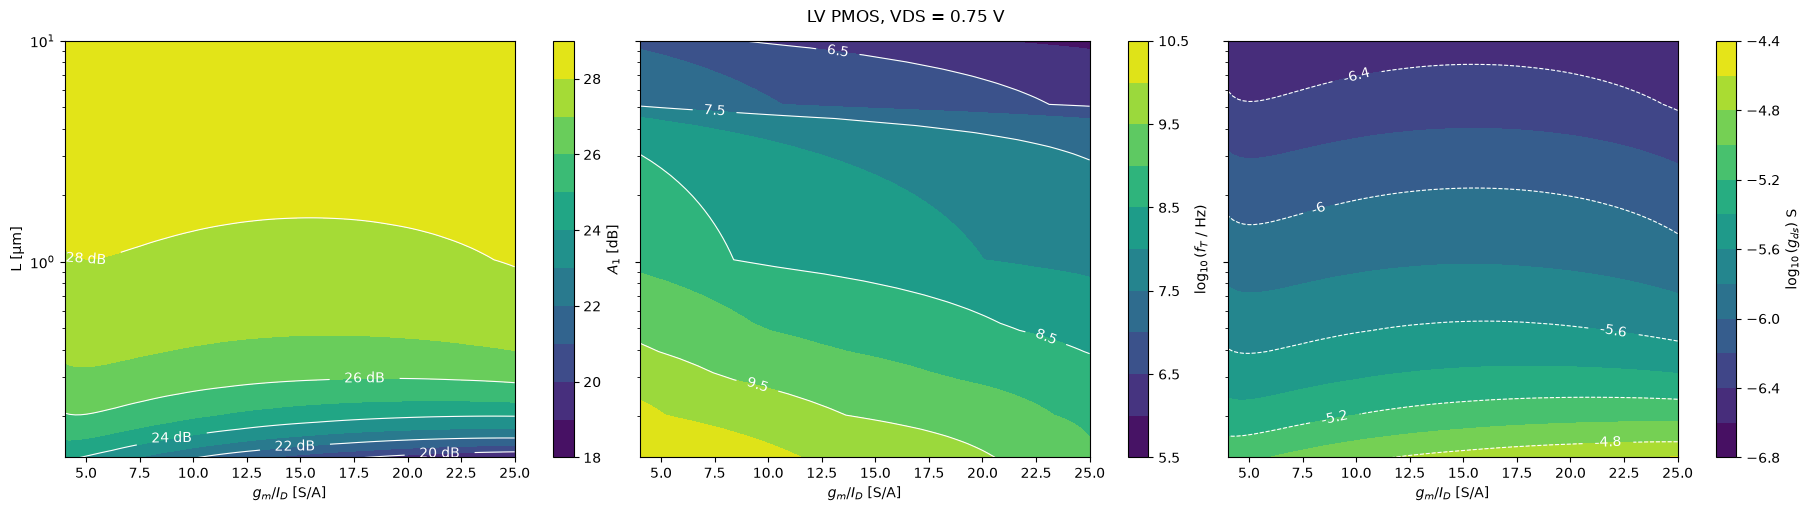

In [24]:
gm_id_output_diode = np.linspace(4, 25, 85)       # [S/A]
L_output_diode = np.geomspace(0.13, 10, 60)       # [µm]
VDS_output_diode = 0.75                           # [V], used for the 2D plots

gm_output_diode = gm_id_output_diode * id_output_mirror
# With gm/ID as input (mode 3), pygmid returns an array of shape (len(L), len(gm_id))
gds_output_diode = gm_output_diode / lv_pmos.lookup('GM_GDS', GM_ID=gm_id_output_diode, L=L_output_diode, VDS=VDS_output_diode, VSB=0) # intrinsic gain [V/V]
gm_cgg_output_diode = lv_pmos.lookup('GM_CGG', GM_ID=gm_id_output_diode, L=L_output_diode, VDS=VDS_output_diode, VSB=0) # transit frequency [Hz]

gain_output_stage = gm_output_mirror / (gds_output_mirror + gds_output_diode + 1/1e6)
gain_output_stage_dB = 20*np.log10(gain_output_stage)
X, Y = np.meshgrid(gm_id_output_diode, L_output_diode)   # grid with the same shape as the tables
fT_output_diode = gm_cgg_output_diode / (2*np.pi)          # GM_CGG ist omega_T [rad/s] -> fT [Hz]

# (Daten, Colorbar-Label, Format der Linienbeschriftung)
plots = [
    (gain_output_stage_dB,        '$A_1$ [dB]',            '%g dB'),
    (np.log10(fT_output_diode),     '$\\log_{10}(f_T$ / Hz)',       '%g'),
    (np.log10(gds_output_diode),        '$\\log_{10}(g_{ds})$ S',            '%g'),
]

fig, axs = plt.subplots(1, 3, figsize=(18, 5), sharey=True, constrained_layout=True)
for ax, (z, label, fmt) in zip(axs, plots):
    cf = ax.contourf(X, Y, z, levels=nice_levels(z), cmap='viridis')
    fig.colorbar(cf, ax=ax, label=label)
    cs = ax.contour(X, Y, z, levels=cf.levels[::2], colors='white', linewidths=0.8)
    ax.clabel(cs, fmt=fmt)
    ax.set(xlabel='$g_m/I_D$ [S/A]', yscale='log')
axs[0].set_ylabel('L [µm]')
fig.suptitle(f'LV PMOS, VDS = {VDS_output_diode} V')
plt.show()

In [25]:
gm_id_output_diode = 13
L_output_diode = 1
gm_output_diode = gm_id_output_diode * id_output_mirror
gds_output_diode = gm_output_diode / lv_nmos.lookup('GM_GDS', GM_ID=gm_id_output_diode, L=L_output_diode, VDS=VDD/2, VSB=0)
W_output_diode_exact = id_output_mirror / lv_nmos.lookup('ID_W', GM_ID=gm_id_output_diode, L=L_output_diode, VDS=VDD/2, VSB=0)
W_output_diode = round(W_output_diode_exact / 0.5) * 0.5
gain_output_stage = gm_output_mirror / (gds_output_mirror + gds_output_diode + 1e-6)
gain_output_stage_dB = 20*np.log10(gain_output_stage)
print('-'*60)
print("Output diode")
print('-'*60)
print(f"Id:     {id_output_mirror*1e6:.3f} μA")
print(f"gm/Id:  {gm_id_output_diode} 1/V")
print(f"gm:     {gm_output_diode*1e3:.3f} mS")
print(f"gds:    {gds_output_diode*1e6:.3f} μS")
print(f"R0:     {1/gds_output_diode*1e-3:.3f} kOhm")
print(f"Length: {L_output_diode} μm")
print(f"Width:  {W_output_diode} μm, rounded from: {W_output_diode_exact:.3f} μm")
print('-'*60)
print(f"Gain output stage: {gain_output_stage:.3f}/ {gain_output_stage_dB:.3f} dB")

------------------------------------------------------------
Output diode
------------------------------------------------------------
Id:     25.641 μA
gm/Id:  13 1/V
gm:     0.333 mS
gds:    8.920 μS
R0:     112.112 kOhm
Length: 1 μm
Width:  9.5 μm, rounded from: 9.522 μm
------------------------------------------------------------
Gain output stage: 15.892/ 24.023 dB


In [26]:
gm_id = 15
# Enable Buffer and Enable Switches
# Minimum Size as this is digital
W_EN = 0.15
L_EN = 0.13

L_DP = 5                # educated guess, some tradeoff between size / gain / speed
gm_DP = gm_min
id_DP = gm_DP / gm_id

print("-"*60)
print("Differential Pair")
print("-"*60)
print(f"gm/Id:  {gm_id} 1/V")
print(f"gm:     {gm_min*1e3} mS")
print(f"Id:     {id_DP*1e6} μA")
# Vgs of NMOS
print(f"Bias Voltages:")
print("-" * 60)
Vgs_NMOS = Vcm_in
print(f"Vgs_NMOS = {Vgs_NMOS} V")

# Vds of NMOS
Vds_NMOS = Vcm_out
print(f"Vds_NMOS = {Vds_NMOS} V")
print("-" * 60 + "\n")

# Transconductance (gm)
print(f"Transconductance (gm):")
print("-" * 60)
gm_id_NMOS = lv_nmos.lookup("GM_ID", L=l, VGS=Vgs_NMOS, VDS=Vds_NMOS, VSB=0)
print(f"gm/ID(L, VGS, VDS, VSB) = {round(float(gm_id_NMOS), 2)} uS/uA")
gm_NMOS = i_out * gm_id_NMOS
print(f"gm_NMOS = {round(float(gm_NMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Output Conductance (gds)
print(f"Output Conductance (gds):")
print("-" * 60)
gm_gds_NMOS = lv_nmos.lookup("GM_GDS", L=l, VGS=Vgs_NMOS, VDS=Vds_NMOS, VSB=0)
print(f"gm/gds(L, VGS, VDS, VSB) = {round(float(gm_gds_NMOS), 2)}")
gds_NMOS = gm_NMOS / gm_gds_NMOS
print(f"gds_NMOS = {round(float(gds_NMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Gate capacitance (Cgg), Cgg = Cgs + Cgb + Cdb
print(f"Gate capacitance (Cgg), Cgg = Cgs + Cgb + Cdb:")
print("-" * 60)
gm_cgg_NMOS = lv_nmos.lookup("GM_CGG", L=l, VGS=Vgs_NMOS, VDS=Vds_NMOS, VSB=0)
Cgg_NMOS = gm_NMOS / gm_cgg_NMOS
print(f"Cgg_NMOS = {round(float(Cgg_NMOS) * 1e15, 2)}fF")
print("-" * 60 + "\n")

# Transit Frequency (fT) @ current gain = 1
print(f"Transit Frequency (fT) @ current gain = 1:")
f_T_NMOS = gm_cgg_NMOS / (2 * np.pi)
print(f"f_T_NMOS = {round(float(f_T_NMOS) * 1e-9, 2)}GHz")
print("-" * 60 + "\n")

# Width (W)
print(f"Width (W):")
print("-" * 60)
id_w_NMOS = lv_nmos.lookup("ID_W", L=l, VGS=Vgs_NMOS, VDS=Vds_NMOS, VSB=0)
print(f"ID/W(L, VGS, VDS, VSB) = {round(float(id_w_NMOS * 1e6), 2)} uA/um")
w_NMOS = i_out / id_w_NMOS
print(f"w_NMOS = {round(float(w_NMOS), 2)}um")
print("-" * 60 + "\n")

# Thermal Noise PSD at 1Hz (STH)
print(f"Thermal Noise PSD at 1Hz (STH):")
print("-" * 60)
sth_gm = lv_nmos.lookup('STH_GM', GM_ID=gm_id_NMOS, L=l, VDS=Vds_NMOS, VSB=0)
sth = sth_gm * gm_NMOS
print(f"STH(gm/ID, L, VDS, VSB) = {round(float(sth * 1e24), 2)} pV²/Hz (thermal noise psd at 1 Hz)")
print("-" * 60 + "\n")

# Flicker Corner Frequency (fco)
print(f"Flicker Corner Frequency (fco):")
print("-" * 60)
fco = lv_nmos.lookup('SFL_STH', GM_ID=gm_id_NMOS, L=l, VDS=Vds_NMOS, VSB=0)
print(f"fco(gm/ID, L, VDS, VSB) = {round(float(fco * 1e-6), 2)} MHz (flicker corner frequency @ flicker noise PSD = thermal noise PSD)")
print("=" * 60)

------------------------------------------------------------
Differential Pair
------------------------------------------------------------
gm/Id:  15 1/V
gm:     5.063430318072861 mS
Id:     337.5620212048574 μA
Bias Voltages:
------------------------------------------------------------
Vgs_NMOS = 0.75 V
Vds_NMOS = 0.75 V
------------------------------------------------------------

Transconductance (gm):
------------------------------------------------------------


NameError: name 'l' is not defined

------------------------------------------------------------
Differential Pair
------------------------------------------------------------
gm/Id:  15 1/V
gm:     5.063430318072861 mS
Id:     337.5620212048574 μA
Bias Voltages:
------------------------------------------------------------
Vgs_NMOS = 0.75 V
Vds_NMOS = 0.75 V
------------------------------------------------------------

Transconductance (gm):
------------------------------------------------------------


NameError: name 'l' is not defined

In [ ]:
# PMOS Sizing
print("=" * 60)
print("PMOS Sizing:")
print("=" * 60, "\n")

# Vgs of PMOS
print(f"Bias Voltages:")
print("-" * 60)
Vgs_PMOS = VDD - Vcm_in
print(f"Vgs_PMOS = {Vgs_PMOS} V")

# Vds of PMOS
Vds_PMOS = VDD - Vcm_out
print(f"Vds_PMOS = {Vds_PMOS} V")
print("-" * 60 + "\n")

# Transconductance (gm)
print(f"Transconductance (gm):")
print("-" * 60)
gm_id_PMOS = gm_id_NMOS # lv_pmos.lookup("GM_ID", L=l_MA, VGS=Vgs_PMOS, VDS=Vds_PMOS, VSB=0)
print(f"gm/ID(L, VGS, VDS, VSB) = {round(float(gm_id_PMOS), 2)} uS/uA")
gm_PMOS = i_out * gm_id_PMOS
print(f"gm_PMOS = {round(float(gm_PMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Output Conductance (gds)
print(f"Output Conductance (gds):")
print("-" * 60)
gm_gds_PMOS = lv_pmos.lookup("GM_GDS", L=l, VGS=Vgs_PMOS, VDS=Vds_PMOS, VSB=0)
print(f"gm/gds(L, VGS, VDS, VSB) = {round(float(gm_gds_PMOS), 2)}")
gds_PMOS = gm_PMOS / gm_gds_PMOS
print(f"gds_PMOS = {round(float(gds_PMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Gate capacitance (Cgg), Cgg = Cgs + Cgb + Cdb
print(f"Gate capacitance (Cgg), Cgg = Cgs + Cgb + Cdb:")
print("-" * 60)
gm_cgg_PMOS = lv_pmos.lookup("GM_CGG", L=l, VGS=Vgs_PMOS, VDS=Vds_PMOS, VSB=0)
Cgg_PMOS = gm_PMOS / gm_cgg_PMOS
print(f"Cgg_PMOS = {round(float(Cgg_PMOS) * 1e15, 2)}fF")
print("-" * 60 + "\n")

# Transit Frequency (fT) @ current gain = 1
print(f"Transit Frequency (fT) @ current gain = 1:")
f_T_PMOS = gm_cgg_PMOS / (2 * np.pi)
print(f"f_T_PMOS = {round(float(f_T_PMOS) * 1e-9, 2)}GHz")
print("-" * 60 + "\n")

# Width (W)
print(f"Width (W):")
print("-" * 60)
id_w_PMOS = lv_pmos.lookup("ID_W", L=l, VGS=Vgs_PMOS, VDS=Vds_PMOS, VSB=0)
print(f"ID/W(L, VGS, VDS, VSB) = {round(float(id_w_PMOS * 1e6), 2)} uA/um")
w_PMOS = i_out / id_w_PMOS
print(f"w_PMOS = {round(float(w_PMOS), 2)}um")
print("-" * 60 + "\n")

# Thermal Noise PSD at 1Hz (STH)
print(f"Thermal Noise PSD at 1Hz (STH):")
print("-" * 60)
sth_gm = lv_pmos.lookup('STH_GM', GM_ID=gm_id_PMOS, L=l, VDS=Vds_PMOS, VSB=0)
sth = sth_gm * gm_PMOS
print(f"STH(gm/ID, L, VDS, VSB) = {round(float(sth * 1e24), 2)} pV²/Hz (thermal noise psd at 1 Hz)")
print("-" * 60 + "\n")

# Flicker Corner Frequency (fco)
print(f"Flicker Corner Frequency (fco):")
print("-" * 60)
fco = lv_pmos.lookup('SFL_STH', GM_ID=gm_id_PMOS, L=l, VDS=Vds_PMOS, VSB=0)
print(f"fco(gm/ID, L, VDS, VSB) = {round(float(fco * 1e-6), 2)} MHz (flicker corner frequency @ flicker noise PSD = thermal noise PSD)")
print("=" * 60)

In [ ]:
# PMOS / NMOS Width Ratio
w_ratio = w_PMOS / w_NMOS
print(f"PMOS/NMOS Width Ratio (W_PMOS/W_NMOS) = {round(float(w_ratio), 2)}")

# Define Widths and Fingers

In [ ]:
def calculate_finger_options(width1_um, width2_um, target_ratio, min_finger_width=1.0, max_finger_width=20.0, max_options=10, finger_width_step=1.0):
    """
    Calculate practicable finger configurations for two transistors maintaining their width ratio.
    Finger widths are constrained to multiples of finger_width_step (default: 0.5um).
    Only returns configurations with an even number of fingers.
    Both transistors must have the SAME number of fingers.
    
    Parameters:
    -----------
    width1_um : float
        Width of first transistor in micrometers (e.g., PMOS)
    width2_um : float
        Width of second transistor in micrometers (e.g., NMOS)
    target_ratio : float
        Target width ratio (width1 / width2)
    min_finger_width : float
        Minimum practical finger width in micrometers (default: 1.0um)
    max_finger_width : float
        Maximum practical finger width in micrometers (default: 20.0um)
    max_options : int
        Maximum number of options to return (default: 10)
    finger_width_step : float
        Step size for finger width in micrometers (default: 1.0um)
    
    Returns:
    --------
    list of tuples : (nf, fw1, fw2, actual_ratio, error_percent)
        nf: number of fingers (same for both transistors)
        fw1: finger width for transistor 1
        fw2: finger width for transistor 2
        List of viable configurations sorted by error and preference
    """
    
    combinations = []
    
    # Try different even numbers of fingers
    # Start from 2 and go up to a reasonable maximum
    max_nf = int(max(width1_um, width2_um) / min_finger_width) + 2
    
    for nf in range(2, max_nf + 1, 2):  # Only even numbers
        # Calculate required finger widths for this number of fingers
        fw1_exact = width1_um / nf
        fw2_exact = width2_um / nf
        
        # Round to nearest finger_width_step
        fw1 = round(fw1_exact / finger_width_step) * finger_width_step
        fw2 = round(fw2_exact / finger_width_step) * finger_width_step
        
        # Check if both finger widths are within acceptable range
        if (min_finger_width <= fw1 <= max_finger_width and 
            min_finger_width <= fw2 <= max_finger_width):
            
            # Calculate actual widths with rounded finger widths
            actual_width1 = nf * fw1
            actual_width2 = nf * fw2
            
            # Calculate actual ratio
            actual_ratio = actual_width1 / actual_width2
            
            # Calculate percentage error from target ratio
            error_percent = abs(actual_ratio - target_ratio) / target_ratio * 100
            
            # Add to combinations
            combinations.append((nf, fw1, fw2, actual_ratio, error_percent))
    
    # Sort by preference: minimize error (but less aggressive), then prefer good finger widths
    def preference_score(combo):
        nf, fw1, fw2, actual_ratio, error_percent = combo
        # Primary: minimize ratio error (less aggressive weight to allow more error)
        error_score = error_percent * 2  # Reduced from 10 to 2
        # Secondary: prefer finger widths around 3-8um range
        width_score1 = abs(fw1 - 5.0)
        width_score2 = abs(fw2 - 5.0)
        # Tertiary: prefer fewer fingers
        finger_score = nf * 0.01
        return error_score + width_score1 + width_score2 + finger_score
    
    combinations.sort(key=preference_score)
    
    return combinations[:max_options]

In [ ]:
# Calculate finger configurations for all transistors
print("=" * 60)
print('Finger Configuration Options:')
print("=" * 60 + "\n")

# Inverter A
print("Inverter A:")
print("-" * 60)
print(f"Target: PMOS width = {round(float(w_PMOS), 2)}um, NMOS width = {round(float(w_NMOS), 2)}um")
print(f"Target ratio (PMOS/NMOS) = {round(float(w_ratio), 2)}")
print("-" * 60 + "\n")

inverter_a_options = calculate_finger_options(
    round(float(w_PMOS), 2), 
    round(float(w_NMOS), 2), 
    float(w_ratio),
    min_finger_width=1.0,
    max_finger_width=20.0,
    max_options=10,
    finger_width_step=1.0
)

for i, (nf, fw_p, fw_n, actual_ratio, error_pct) in enumerate(inverter_a_options[:5], 1):
    actual_w_p = nf * fw_p
    actual_w_n = nf * fw_n
    print(f"Option {i}:")
    print(f"  Number of fingers: {nf} (same for both)")
    print(f"  PMOS: {nf} fingers × {round(fw_p, 2)}um/finger = {round(actual_w_p, 2)}um")
    print(f"  NMOS: {nf} fingers × {round(fw_n, 2)}um/finger = {round(actual_w_n, 2)}um")
    print(f"  Actual ratio: {round(actual_ratio, 2)}, Error: {round(error_pct, 2)}%")
    print("-" * 60 + "\n")

print("Final Widths for Inverter A:")
# Extract values from the best option (first in the list)
if inverter_a_options:
    NF_PMOS, w_NF_PMOS, w_NF_NMOS, _, _ = inverter_a_options[3]
    w_PMOS = w_NF_PMOS * NF_PMOS
    print(f"w_PMOS = w_NF_PMOS * NF_PMOS = {round(w_NF_PMOS, 2)}um * {NF_PMOS} = {round(w_PMOS, 2)}um")

    NF_NMOS = NF_PMOS  # Same number of fingers for both
    w_NMOS = w_NF_NMOS * NF_NMOS
    print(f"w_NMOS = w_NF_NMOS * NF_NMOS = {round(w_NF_NMOS, 2)}um * {NF_NMOS} = {round(w_NMOS, 2)}um")
else:
    print("No suitable finger configuration found!")
print("=" * 60)

In [ ]:
# NMOS Sizing with final width
print("=" * 60)
print("NMOS Sizing with final width:")
print("=" * 60, "\n")

# Output Current (i_out)
print(f"Output Current (i_out):")
print("-" * 60)
i_out = w_NMOS * id_w_NMOS
print(f"Output current with final width: i_out = w_NMOS * ID/W = {round(float(i_out) * 1e3, 2)} mA")
print("-" * 60 + "\n")

# Transconductance (gm)
print(f"Transconductance (gm):")
print("-" * 60)
gm_NMOS = i_out * gm_id_NMOS
print(f"gm_NMOS = {round(float(gm_NMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Output Conductance (gds)
print(f"Output Conductance (gds):")
print("-" * 60)
gds_NMOS = gm_NMOS / gm_gds_NMOS
print(f"gds_NMOS = {round(float(gds_NMOS) * 1e3, 2)}mS")
print("-" * 60)

In [ ]:
# PMOS Sizing with final width
print("=" * 60)
print("PMOS Sizing with final width:")
print("=" * 60, "\n")

# Output Current (i_out)
print(f"Output Current (i_out):")
print("-" * 60)
i_out = w_PMOS * id_w_PMOS
print(f"Output current with final width: i_out = w_PMOS * ID/W = {round(float(i_out) * 1e3, 2)} mA")
print("-" * 60 + "\n")

# Transconductance (gm)
print(f"Transconductance (gm):")
print("-" * 60)
gm_PMOS = i_out * gm_id_PMOS
print(f"gm_PMOS = {round(float(gm_PMOS) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Output Conductance (gds)
print(f"Output Conductance (gds):")
print("-" * 60)
gds_PMOS = gm_PMOS / gm_gds_PMOS
print(f"gds_PMOS = {round(float(gds_PMOS) * 1e3, 2)}mS")
print("-" * 60)

In [ ]:
# Transconductance of inverter
print(f"Transconductance of inverter:")
print("-" * 60)
gm_A = gm_NMOS + gm_PMOS
print(f"gm_A = gm_NMOS + gm_PMOS = {round(float(gm_A) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Output Conductance of inverter
print(f"Output Conductance of inverter:")
print("-" * 60)
gds_A = gds_NMOS + gds_PMOS
print(f"gds_A = gds_NMOS + gds_PMOS = {round(float(gds_A) * 1e3, 2)}mS")
print("-" * 60 + "\n")

# Open-Loop Gain (Aol) of inverter
print(f"Open-Loop Gain (Aol) of inverter:")
print("-" * 60)
Aol_A = - gm_A / gds_A
print(f"Aol_A = {round(float(Aol_A), 2)} = {round(20 * np.log10(float(abs(Aol_A))), 2)} dB")
print("-" * 60 + "\n")

# Output Resistance (Rout) of inverter
print(f"Output Resistance (Rout) of inverter:")
print("-" * 60)
Rout_A = 1 / gds_A if gds_A != 0 else float('inf')
print(f"Rout_A = 1 / gds_A = {round(float(Rout_A), 2)} Ohms")
print("-" * 60 + "\n")

# Open-Loop Cut-Off Frequency (fcu) of inverter
print(f"Open-Loop Cut-Off Frequency (fcu) of inverter:")
print("-" * 60)
fcu_A = 1 / (2 * np.pi * Rout_A * C_load)
print(f"fcu_A = 1 / (2 * pi * Rout_A * C_load) = {round(float(fcu_A) * 1e-6, 2)} MHz")
print("-" * 60 + "\n")

# Unity-Gain Frequency (fT) of inverter
print(f"Unity-Gain Frequency (fT) of inverter:")
print("-" * 60)
fT_A = gm_A / (2 * np.pi * C_load)
print(f"fT_A = gm_A / (2 * pi * C_load) = {round(float(fT_A) * 1e-6, 2)} MHz")
print("=" * 60)

# Area Estimation



In [ ]:
print("=" * 60)
print('Inverter - Area Estimation:')
print("=" * 60)

area_inverter = w_PMOS * l + w_NMOS * l
print(f"area_inverter = {round(float(area_inverter), 2)}um^2")
print("=" * 60)